# Assignment 1 - Building a Vision Model with Keras

In this assignment, you will build a simple vision model using Keras. The goal is to classify images from the Fashion MNIST dataset, which contains images of clothing items.

You will:
1. Load and inspect the Fashion MNIST dataset.
2. Run a simple baseline model to establish a performance benchmark.
3. Build and evaluate a simple CNN model, choosing appropriate loss and metrics.
4. Design and run controlled experiments on one hyperparameter (e.g., number of filters, kernel size, etc.) and one regularization technique (e.g., dropout, L2 regularization).
5. Analyze the results and visualize the model's performance.

# 1. Loading and Inspecting the Dataset

Fashion MNIST is a dataset of grayscale images of clothing items, with 10 classes. Each image is 28x28 pixels, like the MNIST dataset of handwritten digits. Keras provides a convenient way to load this dataset. 

In this section, you should:

- [ ] Inspect the shapes of the training and test sets to confirm their size and structure.
- [ ] Convert the labels to one-hot encoded format if necessary. (There is a utility function in Keras for this.)
- [ ] Visualize a few images from the dataset to understand what the data looks like.

In [16]:
from tensorflow.keras.datasets import fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Normalize the pixel values to be between 0 and 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Classes in the Fashion MNIST dataset
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

In [31]:
# Inspect the shapes of the datasets
print(f'X_train shape: {X_train.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_test shape: {y_test.shape}')

# Convert labels to one-hot encoding
from tensorflow.keras.utils import to_categorical
y_train_code = to_categorical(y_train, num_classes=len(class_names))
y_test_code = to_categorical(y_test, num_classes=len(class_names))


X_train shape: (60000, 28, 28)
y_train shape: (60000,)
X_test shape: (10000, 28, 28)
y_test shape: (10000,)


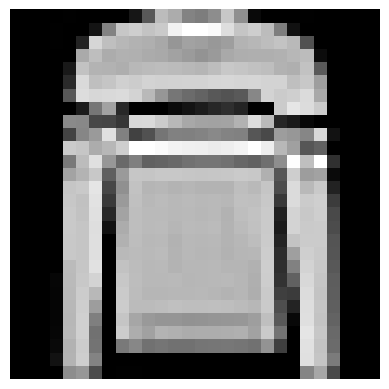

In [32]:
import matplotlib.pyplot as plt
# Verify the data looks as expected
import numpy as np

plt.imshow(X_train[5], cmap="gray")
plt.axis("off")
plt.show()

Reflection: Does the data look as expected? How is the quality of the images? Are there any issues with the dataset that you notice?

The dataset is very pixelated and simplified. Since the color values are normalized, there is no data on hue of the image.

# 2. Baseline Model

In this section, you will create a linear regression model as a baseline. This model will not use any convolutional layers, but it will help you understand the performance of a simple model on this dataset.
You should:
- [ ] Create a simple linear regression model using Keras.
- [ ] Compile the model with an appropriate loss function and optimizer.
- [ ] Train the model on the training set and evaluate it on the test set.

A linear regression model can be created using the `Sequential` API in Keras. Using a single `Dense` layer with no activation function is equivalent to a simple linear regression model. Make sure that the number of units in the output layer matches the number of classes in the dataset.

Note that for this step, we will need to use `Flatten` to convert the 2D images into 1D vectors before passing them to the model. Put a `Flatten()` layer as the first layer in your model so that the 2D image data can be flattened into 1D vectors.

In [37]:
from keras.models import Sequential
from keras.layers import Dense, Flatten

# Create a simple linear regression model
model = Sequential()

# You can use `model.add(<layer>)` to add layers to the model
model.add(Flatten(input_shape=(28,28)))  # Convert 2D into 1D vectors
model.add(Dense(64, activation='relu'))  # 64 neurons, ReLU activation

# Hidden layer
model.add(Dense(64, activation='relu'))  # 64 neurons, ReLU activation

# Output layer
model.add(Dense(10, activation='softmax'))  # 10 neurons, softmax activation

model.summary()
# Compile the model using `model.compile()`
model.compile(
    loss='categorical_crossentropy', 
    optimizer='sgd', 
    metrics=['accuracy']
)

# Train the model with `model.fit()`
model.fit(
    X_train, # Training data
    y_train_code, # Training labels
    epochs=5, # Number of epochs
    batch_size=32, # Number of samples per batch
    validation_split=0.2 # Use 20% of the data for validation
)

# Evaluate the model with `model.evaluate()`
loss, accuracy = model.evaluate(X_test, y_test_code)

print(f'Loss:     {loss:.2f}')
print(f'Accuracy: {accuracy*100:.2f}%')

c:\Users\kayou\Desktop\DSI\repos\deep_learning\deep-learning-env\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_7 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,050 (215.04 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.7191 - loss: 0.8502 - val_accuracy: 0.7971 - val_loss: 0.5884
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8134 - loss: 0.5395 - val_accuracy: 0.8241 - val_loss: 0.5025
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8305 - loss: 0.4840 - val_accuracy: 0.8322 - val_loss: 0.4708
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8394 - loss: 0.4539 - val_accuracy: 0.8348 - val_loss: 0.4585
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8484 - loss: 0.4322 - val_accuracy: 0.8440 - val_loss: 0.4450
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8363 - loss: 0.4654
Loss:     0.47
Accuracy: 83.63%


Reflection: What is the performance of the baseline model? How does it compare to what you expected? Why do you think the performance is at this level?

**Your answer here**
The performance of this model is 83.6% accuracy, which is not as high as expected. This is possibly due to the flattening of data from 2D to 1D which removes spacial information from data.

# 3. Building and Evaluating a Simple CNN Model

In this section, you will build a simple Convolutional Neural Network (CNN) model using Keras. A convolutional neural network is a type of deep learning model that is particularly effective for image classification tasks. Unlike the basic neural networks we have built in the labs, CNNs can accept images as input without needing to flatten them into vectors.

You should:
- [ ] Build a simple CNN model with at least one convolutional layer (to learn spatial hierarchies in images) and one fully connected layer (to make predictions).
- [ ] Compile the model with an appropriate loss function and metrics for a multi-class classification problem.
- [ ] Train the model on the training set and evaluate it on the test set.

Convolutional layers are designed to accept inputs with three dimensions: height, width and channels (e.g., RGB for color images). For grayscale images like those in Fashion MNIST, the input shape will be (28, 28, 1).

When you progress from the convolutional layers to the fully connected layers, you will need to flatten the output of the convolutional layers. This can be done using the `Flatten` layer in Keras, which doesn't require any parameters.

In [52]:
from keras.layers import Conv2D, Input, MaxPooling2D


# Reshape the data to include the channel dimension
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Create a simple CNN model
model = Sequential()
model.add(Input(shape=(28,28,1)))
model.add(Conv2D(64, kernel_size=(3,3), activation='relu'))  # Convert 2D into 1D vectors
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Flatten())
model.add(Dense(64, activation='relu'))  # 64 neurons, ReLU activation
model.add(Dense(64, activation='relu'))  # 64 neurons, ReLU activation
model.add(Dense(10, activation='softmax'))  # 10 neurons, softmax activation

model.summary()

model.compile(
    loss='categorical_crossentropy', 
    optimizer='sgd', 
    metrics=['accuracy']
)

# Train the model
model.fit(
    X_train, # Training data
    y_train_code, # Training labels
    epochs=5, # Number of epochs
    batch_size=32, # Number of samples per batch
    validation_split=0.2 # Use 20% of the data for validation
)


# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test_code)

print(f'Loss:     {loss:.2f}')
print(f'Accuracy: {accuracy*100:.2f}%')

Model: "sequential_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 26, 26, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_13 (Flatten)            │ (None, 10816)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_36 (Dense)                │ (None, 64)             │       692,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_37 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 697,738 (2.66 MB)

 Trainable params: 697,738 (2.66 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 45s 29ms/step - accuracy: 0.7222 - loss: 0.8120 - val_accuracy: 0.8066 - val_loss: 0.5484
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 34s 23ms/step - accuracy: 0.8133 - loss: 0.5179 - val_accuracy: 0.8294 - val_loss: 0.4835
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 35s 19ms/step - accuracy: 0.8354 - loss: 0.4562 - val_accuracy: 0.8448 - val_loss: 0.4374
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 32s 22ms/step - accuracy: 0.8496 - loss: 0.4164 - val_accuracy: 0.8293 - val_loss: 0.4791
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 33s 22ms/step - accuracy: 0.8601 - loss: 0.3874 - val_accuracy: 0.8636 - val_loss: 0.3800
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8567 - loss: 0.3966
Loss:     0.40
Accuracy: 85.67%


Reflection: Did the CNN model perform better than the baseline model? If so, by how much? What do you think contributed to this improvement?

**Your answer here**
Yes, it did improve in accuracy by approx. 2%. This is while not drastic, it does prove my previous hypothesis that some spacial information of the data was being lost. With the Convo2D, it allows for 2D input which could have improved the accuracy.

# 4. Designing and Running Controlled Experiments

In this section, you will design and run controlled experiments to improve the model's performance. You will focus on one hyperparameter and one regularization technique.
You should:
- [ ] Choose one hyperparameter to experiment with (e.g., number of filters, kernel size, number of layers, etc.) and one regularization technique (e.g., dropout, L2 regularization). For your hyperparameter, you should choose at least three different values to test (but there is no upper limit). For your regularization technique, simply test the presence or absence of the technique.
- [ ] Run experiments by modifying the model architecture or hyperparameters, and evaluate the performance of each model on the test set.
- [ ] Record the results of your experiments, including the test accuracy and any other relevant metrics.
- [ ] Visualize the results of your experiments using plots or tables to compare the performance of different models.

The best way to run your experiments is to create a `for` loop that iterates over a range of values for the hyperparameter you are testing. For example, if you are testing different numbers of filters, you can create a loop that runs the model with 32, 64, and 128 filters. Within the loop, you can compile and train the model, then evaluate it on the test set. After each iteration, you can store the results in a list or a dictionary for later analysis.

Note: It's critical that you re-initialize the model (by creating a new instance of the model) before each experiment. If you don't, the model will retain the weights from the previous experiment, which can lead to misleading results.

In [61]:
# A. Test Hyperparameters
from keras.utils import set_random_seed
def Param_test(hyperparam):
    model = Sequential()
    model.add(Input(shape=(28,28,1)))
    model.add(Conv2D(64, kernel_size=hyperparam, activation='relu'))  # Convert 2D into 1D vectors
    model.add(MaxPooling2D(pool_size=(2,2)))
    model.add(Flatten())
    model.add(Dense(64, activation='relu'))  # 64 neurons, ReLU activation
    model.add(Dense(64, activation='relu'))  # 64 neurons, ReLU activation
    model.add(Dense(10, activation='softmax'))  # 10 neurons, softmax activation

    model.compile(
        loss='categorical_crossentropy', 
        optimizer='sgd', 
        metrics=['accuracy']
    )
    return model

hyperparam = [(1,1),(3,3),(10,10)]
result=[]
for param in hyperparam:
    print(f"kernel_size={param}")
    set_random_seed(42)
    model=Param_test(param)
    record=model.fit(
        X_train, # Training data
        y_train_code, # Training labels
        epochs=5, # Number of epochs
        batch_size=32, # Number of samples per batch
        validation_split=0.2 # Use 20% of the data for validation
    )
    loss, accuracy = model.evaluate(X_test, y_test_code)

    print(f'Loss:     {loss:.2f}')
    print(f'Accuracy: {accuracy*100:.2f}%')

    result.append({
        'Kernel Size':str(param),
        'Val Accuracy, %': round(record.history['val_accuracy'][-1]*100,2),
        'Test Accuracy, %': round(accuracy*100,2),
        'Test Loss': round(loss, 4)
    })
        
print(result)



kernel_size=(1, 1)
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 30s 19ms/step - accuracy: 0.6719 - loss: 0.9504 - val_accuracy: 0.7982 - val_loss: 0.5801
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 26s 17ms/step - accuracy: 0.7968 - loss: 0.5656 - val_accuracy: 0.8130 - val_loss: 0.5201
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 27s 18ms/step - accuracy: 0.8123 - loss: 0.5165 - val_accuracy: 0.8251 - val_loss: 0.4890
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 26s 17ms/step - accuracy: 0.8232 - loss: 0.4853 - val_accuracy: 0.8310 - val_loss: 0.4681
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 24s 16ms/step - accuracy: 0.8302 - loss: 0.4633 - val_accuracy: 0.8349 - val_loss: 0.4531
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8258 - loss: 0.4827
Loss:     0.48
Accuracy: 82.58%
kernel_size=(3, 3)
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 28s 18ms/step - accuracy: 0.7156 - loss: 0.8214 - val_accuracy: 0.8110 - val_loss: 0.5365
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 25s 16ms/step - accuracy: 0.

In [63]:
import pandas as pd
results_df = pd.DataFrame(result)
print("\n=== Hyperparameter Comparison ===")
print(results_df.to_string(index=False))


=== Hyperparameter Comparison ===
Kernel Size  Val Accuracy, %  Test Accuracy, %  Test Loss
     (1, 1)            83.49             82.58     0.4827
     (3, 3)            86.58             85.83     0.3989
   (10, 10)            86.55             85.73     0.4054


In [ ]:
# B. Test presence or absence of regularization
from keras.layers import Dropout

def reg_test(dropout_rate=0.0):
    model = Sequential()
    model.add(Input(shape=(28,28,1)))
    model.add(Conv2D(64, kernel_size=(3,3), activation='relu'))  # Convert 2D into 1D vectors
    model.add(MaxPooling2D(pool_size=(2,2)))
    model.add(Flatten())
    model.add(Dense(64, activation='relu'))  # 64 neurons, ReLU activation
    if dropout_rate > 0:
        model.add(Dropout(dropout_rate))

    model.add(Dense(64, activation='relu'))  # 64 neurons, ReLU activation
    if dropout_rate > 0:
        model.add(Dropout(dropout_rate))

    model.add(Dense(10, activation='softmax'))  # 10 neurons, softmax activation

    model.compile(
        loss='categorical_crossentropy', 
        optimizer='sgd', 
        metrics=['accuracy']
    )
    return model

dp_rate = [0.0, 0.5]
result=[]
for param in dp_rate:
    print(f"dropout_rate={param}")
    set_random_seed(42)

    model=reg_test(dropout_rate=param)
    record=model.fit(
        X_train, # Training data
        y_train_code, # Training labels
        epochs=5, # Number of epochs
        batch_size=32, # Number of samples per batch
        validation_split=0.2 # Use 20% of the data for validation
    )
    loss, accuracy = model.evaluate(X_test, y_test_code)

    print(f'Loss:     {loss:.2f}')
    print(f'Accuracy: {accuracy*100:.2f}%')

    result.append({
        'Dropout Rate':str(param),
        'Val Accuracy, %': round(record.history['val_accuracy'][-1]*100,2),
        'Test Accuracy, %': round(accuracy*100,2),
        'Test Loss': round(loss, 4)
    })
        
print(result)


dropout_rate=0.0
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 27s 17ms/step - accuracy: 0.7156 - loss: 0.8214 - val_accuracy: 0.8110 - val_loss: 0.5365
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 26s 17ms/step - accuracy: 0.8183 - loss: 0.5058 - val_accuracy: 0.8393 - val_loss: 0.4624
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 29s 19ms/step - accuracy: 0.8404 - loss: 0.4479 - val_accuracy: 0.8512 - val_loss: 0.4280
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 29s 19ms/step - accuracy: 0.8553 - loss: 0.4102 - val_accuracy: 0.8582 - val_loss: 0.4015
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 30s 20ms/step - accuracy: 0.8644 - loss: 0.3813 - val_accuracy: 0.8658 - val_loss: 0.3823
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8583 - loss: 0.3989
Loss:     0.40
Accuracy: 85.83%
dropout_rate=0.5
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 32s 20ms/step - accuracy: 0.5068 - loss: 1.3229 - val_accuracy: 0.7549 - val_loss: 0.6520
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 25s 17ms/step - accuracy: 0.681

In [67]:
results_df = pd.DataFrame(result)
print("\n=== Dropout rate effect on model ===")
print(results_df.to_string(index=False))


=== Dropout rate effect on model ===
Dropout Rate  Val Accuracy, %  Test Accuracy, %  Test Loss
         0.0            86.58             85.83     0.3989
         0.5            82.53             82.03     0.5105


Reflection: Report on the performance of the models you tested. Did any of the changes you made improve the model's performance? If so, which ones? What do you think contributed to these improvements? Finally, what combination of hyperparameters and regularization techniques yielded the best performance?

**Your answer here**

Having optimal kernel_size has noticible improvement to the model's performance. The dropout_rate of 0.5 seems to have negative effect on the accuracy of the model.
Overall, kernel size of (3,3) without dropout technique yielded the best performance.

# 5. Training Final Model and Evaluation

In this section, you will train the final model using the best hyperparameters and regularization techniques you found in the previous section. You should:
- [ ] Compile the final model with the best hyperparameters and regularization techniques.
- [ ] Train the final model on the training set and evaluate it on the test set.
- [ ] Report the final model's performance on the test set, including accuracy and any other relevant metrics.

In [68]:
model = Sequential()
model.add(Input(shape=(28,28,1)))
model.add(Conv2D(64, kernel_size=(3,3), activation='relu'))  # Convert 2D into 1D vectors
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Flatten())
model.add(Dense(64, activation='relu'))  # 64 neurons, ReLU activation
model.add(Dense(64, activation='relu'))  # 64 neurons, ReLU activation
model.add(Dense(10, activation='softmax'))  # 10 neurons, softmax activation

model.compile(
    loss='categorical_crossentropy', 
    optimizer='sgd', 
    metrics=['accuracy']
)

# Train the model
model.fit(
    X_train, # Training data
    y_train_code, # Training labels
    epochs=5, # Number of epochs
    batch_size=32, # Number of samples per batch
    validation_split=0.2 # Use 20% of the data for validation
)


# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test_code)

print(f'Loss:     {loss:.2f}')
print(f'Accuracy: {accuracy*100:.2f}%')
print(f'')

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.7239 - loss: 0.8029 - val_accuracy: 0.8094 - val_loss: 0.5325
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 17s 12ms/step - accuracy: 0.8154 - loss: 0.5101 - val_accuracy: 0.8383 - val_loss: 0.4668
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 23s 15ms/step - accuracy: 0.8406 - loss: 0.4472 - val_accuracy: 0.8521 - val_loss: 0.4264
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 46s 19ms/step - accuracy: 0.8549 - loss: 0.4070 - val_accuracy: 0.8589 - val_loss: 0.3996
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 24s 16ms/step - accuracy: 0.8656 - loss: 0.3772 - val_accuracy: 0.8670 - val_loss: 0.3765
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8600 - loss: 0.3923
Loss:     0.39
Accuracy: 86.00%



Reflection: How does the final model's performance compare to the baseline and the CNN model? What do you think contributed to the final model's performance? If you had time, what other experiments would you run to further improve the model's performance?

**Your answer here**

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 11/09/2026`
* The branch name for your repo should be: `assignment-1`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_1.ipynb)
    * The Lab 1 notebook (labs/lab_1.ipynb)
    * The Lab 2 notebook (labs/lab_2.ipynb)
    * The Lab 3 notebook (labs/lab_3.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.